<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🧠 长期记忆：Store · 记忆 schema · Trustcall · Memory Agent

**一句话定位**：checkpointer 记"这次对话"，**Store 记"这个用户"**；记忆要有 schema（profile / collection / instructions），更新用 Trustcall 打补丁而不是整体重写；agent 自己决定何时、往哪种记忆写。
> 覆盖 module-5 全部；`笔记/04` 讲过 Store 基本用法，这里只讲它没讲的。

</div>

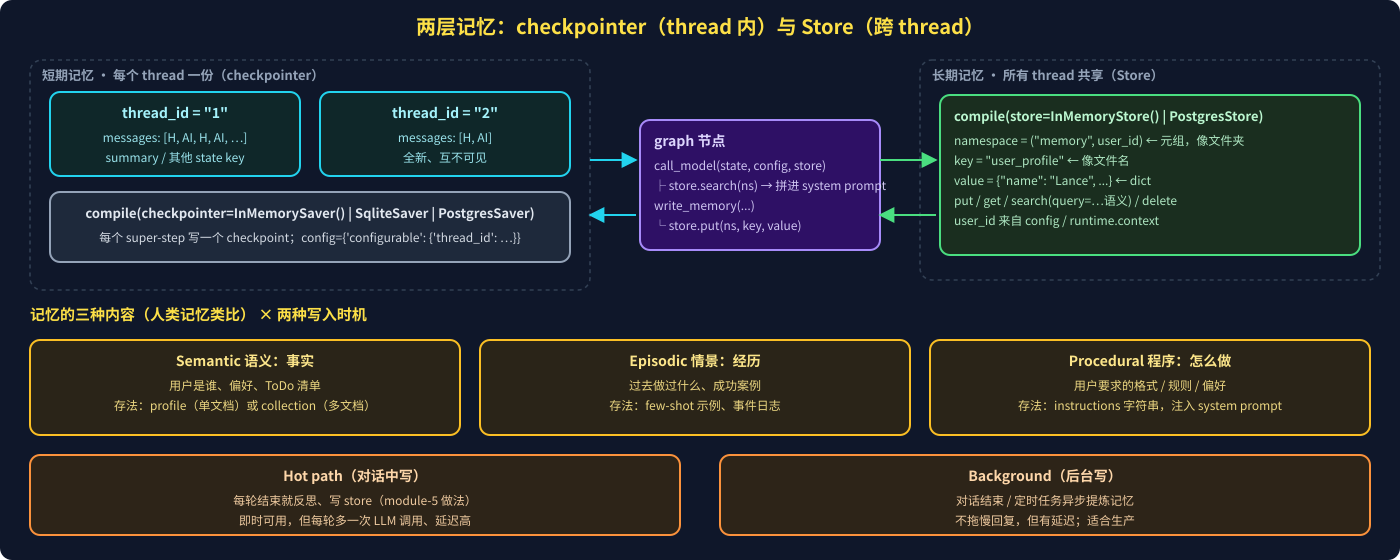

In [ ]:
from IPython.display import SVG
SVG(filename="assets/10_memory_architecture.svg")

### 1️⃣ Store API 速查

| 操作 | 代码 | 备注 |
|---|---|---|
| 写 / 覆盖 | `store.put(ns, key, value_dict)` | 同 key 覆盖 |
| 精确读 | `store.get(ns, key)` → `Item`（`.value` `.key` `.created_at`） | 不存在返回 `None` |
| 列出 / 过滤 | `store.search(ns, filter={"status": "open"}, limit=10)` | 返回 `list[SearchItem]` |
| 🆕 语义检索 | `store.search(ns, query="喜欢什么运动")` | 需 `InMemoryStore(index={"embed": emb, "dims": 1536})` |
| 删除 | `store.delete(ns, key)` | |
| 节点里拿到 store | 参数 `store: BaseStore` · `runtime.store` · `get_store()` | 三种等价 |

```python
from langgraph.store.memory import InMemoryStore
from langchain_openai import OpenAIEmbeddings
store = InMemoryStore(index={"embed": OpenAIEmbeddings(model="text-embedding-3-small"), "dims": 1536})
store.put(("memories", "u1"), "m1", {"content": "User likes biking"})        # 默认对 value 全部字段建索引
store.search(("memories", "u1"), query="outdoor sports", limit=3)             # 按相似度排序，Item.score 有值
```
生产用 `PostgresStore`；部署后 SDK：`client.store.put_item / search_items / delete_item`。

### 2️⃣ 三种记忆 schema 怎么选

| | 裸字符串 | **Profile**（单文档） | **Collection**（多文档） |
|---|---|---|---|
| 形态 | `{"memory": "- 名字 Lance\n- 喜欢骑车"}` | 一个 Pydantic 对象，固定字段 | 每条记忆一个 `Item`，key 用 uuid |
| 读 | `get(ns, "user_memory")` | `get(ns, "user_profile")` | `search(ns)` 全拉 / 语义检索 |
| 更新 | LLM 重写整段 | Trustcall **patch** 字段 | Trustcall **patch 旧条 + insert 新条** |
| 适合 | demo | 用户画像等"永远只有一份"的事实 | 事件、ToDo、数量不定的事实 |
| 坑 | 越写越长、丢信息 | schema 复杂时 `with_structured_output` 易出错 | 要自己管 key、去重 |

### 3️⃣ Trustcall：创建 + 增量更新结构化记忆

In [ ]:
# 前置：本节代码共用的对象
import uuid
from typing import Literal
from typing_extensions import TypedDict
from pydantic import BaseModel
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END
from langgraph.store.memory import InMemoryStore

class Memory(BaseModel):
    content: str

model = init_chat_model("openai:gpt-4o")
store = InMemoryStore()
ns = ("memories", "u1")
conversation = [HumanMessage("I like biking")]
msgs = conversation
SYSTEM = "You are a helpful assistant.\n<user_profile>{user_profile}</user_profile>\n<todo>{todo}</todo>\n<instructions>{instructions}</instructions>"

In [ ]:
from trustcall import create_extractor

extractor = create_extractor(
    model,
    tools=[Memory],              # Pydantic schema 当 tool
    tool_choice="Memory",        # 强制输出这个 schema
    enable_inserts=True,         # collection 必开：允许新增；profile 不用
)

# ① 首次提取
r = extractor.invoke({"messages": [SystemMessage("Extract memories"), *conversation]})
r["responses"]         # [Memory(...)]  解析好的对象
r["response_metadata"] # [{"id": tool_call_id}]            新建 → 没有 json_doc_id

# ② 带已有记忆更新：existing = [(doc_id, schema_name, value_dict), ...]
existing = [(item.key, "Memory", item.value) for item in store.search(ns)]
r = extractor.invoke({"messages": msgs, "existing": existing})
for resp, meta in zip(r["responses"], r["response_metadata"]):
    store.put(ns, meta.get("json_doc_id", str(uuid.uuid4())), resp.model_dump(mode="json"))
    #            ↑ 有 json_doc_id = 更新了旧条（PatchDoc）；没有 = 新插入

# profile 版 existing 写法：{"UserProfile": profile_dict}

<div class="dark-info" style="background:#1e293b; color:#e2e8f0; padding:12px 24px; border-left:4px solid #60a5fa; border-radius:4px; width:97%;"><style>.dark-info strong{color:#fbbf24;}</style>

**Trustcall 做了什么**：底层让模型生成 **JSON Patch**（`PatchDoc` 工具：`planned_edits` + `patches`）只改变化的字段，校验失败会自动重试修正。想看它改了什么：`extractor.with_listeners(on_end=spy)`，在 run 树里抓 `chat_model` 的 `tool_calls`（module-5 的 `Spy` 类）。
版本耦合提醒：升级 `langgraph` 后先确认 `trustcall` 兼容（本机 trustcall 0.0.39 + langgraph 1.2 可用）。

</div>

### 4️⃣ Memory Agent 模式（task_mAIstro）：让 agent 自己决定写什么

In [ ]:
class UpdateMemory(TypedDict):
    """Decision on what memory type to update"""
    update_type: Literal["user", "todo", "instructions"]      # 路由用的"假工具"

def task_mAIstro(state, config, store):
    uid = config["configurable"]["user_id"]
    profile = store.search(("profile", uid))                   # 三种记忆分别读出
    todos   = store.search(("todo", uid))
    instr   = store.search(("instructions", uid))
    sys = SYSTEM.format(user_profile=profile, todo=todos, instructions=instr)   # 全部注入 system prompt
    resp = model.bind_tools([UpdateMemory], parallel_tool_calls=False).invoke([SystemMessage(sys)] + state["messages"])
    return {"messages": [resp]}

def route_message(state):                                       # 条件边：没 tool_call → END
    tc = state["messages"][-1].tool_calls
    if not tc: return END
    return {"user": "update_profile", "todo": "update_todos", "instructions": "update_instructions"}[tc[0]["args"]["update_type"]]

# update_* 节点：Trustcall 更新对应 namespace → 返回 ToolMessage（tool_call_id 对应）→ 回到 task_mAIstro 生成最终回复

| 记忆类型 | namespace | 更新方式 | 注入 prompt 的位置 |
|---|---|---|---|
| Profile（语义） | `("profile", uid)` | Trustcall，无 inserts | `<user_profile>` |
| ToDo collection（语义） | `("todo", uid)` | Trustcall，`enable_inserts=True` | `<todo>` |
| Instructions（**程序性**） | `("instructions", uid)` | 普通 LLM 重写一段文字 | `<instructions>`：改变 agent **怎么**创建 ToDo |

与前几节 chatbot 的区别：**不是每轮都写**，而是模型调用 `UpdateMemory` 时才写，且自己选类型。

### 🧭 设计决策 & 坑

| 问题 | 建议 |
|---|---|
| 什么时候写？ | 对话中（hot path）简单但每轮多一次 LLM；生产倾向后台异步提炼 |
| 写什么？ | 只写**用户明确说的事实**，prompt 里禁止推断；冲突以最新为准 |
| namespace 怎么设计 | `(类型, user_id)` 或 `(user_id, 类型)`，再加 `category` 维度（module-6 用 `("todo", category, uid)`） |
| 读太多怎么办 | 语义检索只取 top-k；或把记忆摘要成一段再注入 |
| state vs store | state 用完即弃（thread 内）；store 跨 thread；**别把长期事实塞进 messages** |
| 存储 | 课程 `InMemoryStore` 重启即丢；生产 `PostgresStore`（部署自带） |

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：`compile(checkpointer=…, store=…)` 两层记忆；Store 按 `(namespace, key, value)` 存、按 `user_id` 隔离、可语义检索；记忆要有 schema——**profile 打补丁、collection 补丁 + 插入**（Trustcall）；高级 agent 用一个路由工具自己决定写 profile / collection / instructions（程序性记忆）。

</div>